In [1]:
source(paste0(dirname(getwd()), "/helpers/map.r"))
source(paste0(dirname(getwd()), "/helpers/shortcuts.r"))
source(paste0(dirname(getwd()), "/helpers/config.r"))
source(paste0(dirname(getwd()), "/helpers/themes.r"))

# Ensure figures output directory exists
dir.create(paste0(CIDER_PROJ_DIR, "figs/"), showWarnings = FALSE, recursive = TRUE)

In [2]:
library(ggpubr)
library(patchwork)

# 0 - Read data

In [ ]:
ready <- readRDS(paste0(CIDER_PROJ_DIR, "cpi_ready.rds"))

# Split cohort_broad's residual "Other" bucket into Non-CRC MSI / Other
# (MSS) for every cohort-faceted figure in this notebook -- "Other"
# otherwise mixes MSI-high and microsatellite-stable patients from many
# different tumor types together (see helpers/shortcuts.r::
# split_other_by_msi(), same split already used in Table 1). Level order
# is BROAD_LEVELS_OTHER_SPLIT (helpers/config.r): ICI-Treated / SKCM /
# NSCLC / BLCA / Other MSS / Non-CRC MSI / CRC-MSI -- grouping the two
# MSI-related cohorts together at the end, with Non-CRC MSI placed before
# CRC-MSI, per direction, rather than just appending both Other splits
# after CRC-MSI. Any patient with unresolved
# MSI status falls into "Other (Unknown MSI)", appended at the very end
# only if present, so none silently drop out. cohort_broad_go is rebuilt
# to match -- this mirrors 0_prepare/4_base.ipynb's own cohort_broad_go
# construction exactly, just applied locally to this notebook's copy of
# `ready` rather than the canonical cpi_ready.rds (so every other notebook
# that reads cpi_ready.rds is unaffected by this display-only relabeling).
cohort_other_split_levels <- c(
  BROAD_LEVELS_OTHER_SPLIT,
  intersect("Other (Unknown MSI)", unique(split_other_by_msi(ready$cohort_broad, ready$msi_high)))
)
ready <- ready |>
  mutate(cohort_broad = factor(
    split_other_by_msi(cohort_broad, msi_high),
    levels = cohort_other_split_levels
  )) |>
  group_by(cohort_broad) |>
  mutate(n_broad = n_distinct(sampleId)) |>
  ungroup() |>
  mutate(
    cohort_broad_go = {
      lkp <- distinct(pick(cohort_broad, n_broad)) |> arrange(cohort_broad)
      factor(
        paste0(cohort_broad, " (N = ", n_broad, ")"),
        levels = paste0(lkp$cohort_broad, " (N = ", lkp$n_broad, ")")
      )
    }
  ) |>
  select(-n_broad)

# 1 - Figure function

`response_plot()` now lives in `helpers/themes.r` (sourced above via
`source(".../helpers/themes.r")`) so it can be reused by other notebooks
without duplicating ~60 lines of ggplot code — see
`1_figures/17_response_by_read_confidence.ipynb` for an example that reuses
it unchanged with a read-confidence-filter column in place of a cohort
column.


# 2 - Main figure: overall T-cell infiltration vs response

In [ ]:
main_response_figure <- response_plot(
  ready, "T-cell", "cohort_broad_go",
  title   = "CIDER T-cell Score vs ICI Response",
  y_col   = "cider_score_depth_adj",
  x_dodge = 2
)
set_plot_dims(9, 4); main_response_figure
saveRDS(main_response_figure, paste0(CIDER_PROJ_DIR, "figs/main_response_figure.rds"))

# 2b - Loci-stratified response figures (figure_3b bottom row)

In [ ]:
# Loci-stratified response plots for figure_3b.
# Each reuses response_plot() with the locus-specific gp value.
# Panels are assembled in assemble_main_figures.R.

loci_specs <- list(
  list(key = "trad", gp = "T-cell (TRA/TRD)", title = "T-cell (TRA/TRD)"),
  list(key = "trb",  gp = "T-cell (TRB)",     title = "T-cell (TRB)"),
  list(key = "trg",  gp = "T-cell (TRG)",     title = "T-cell (TRG)")
)

for (spec in loci_specs) {
  p <- response_plot(
    ready, spec$gp, "cohort_broad_go",
    title = spec$title,
    y_col = "cider_score_depth_adj"
  )
  saveRDS(p, paste0(CIDER_PROJ_DIR, "figs/response_loci_", spec$key, ".rds"))
}

# Preview the loci row
set_plot_dims(18, 4)
wrap_plots(
  readRDS(paste0(CIDER_PROJ_DIR, "figs/response_loci_trad.rds")),
  readRDS(paste0(CIDER_PROJ_DIR, "figs/response_loci_trb.rds")),
  readRDS(paste0(CIDER_PROJ_DIR, "figs/response_loci_trg.rds")),
  nrow = 1, guides = "collect"
)

# 2c - Combined TRA/TRD + TRB response figure (figure_3c bottom row)

In [ ]:
# Sum TRA/TRD and TRB scores per patient — single combined αβ-chain score.
combined_trad_trb <- ready |>
  dplyr::filter(gp %in% c("T-cell (TRA/TRD)", "T-cell (TRB)")) |>
  dplyr::group_by(sampleId, cohort_broad_go, responder) |>
  dplyr::summarise(
    cider_score_depth_adj = sum(cider_score_depth_adj, na.rm = TRUE),
    .groups = "drop"
  ) |>
  dplyr::mutate(gp = "T-cell (TRA/TRD + TRB)")

# ── figure_3c bottom row — single faceted plot ────────────────────────────────
# TRA/TRD+TRB and TRG share a common y-axis and scale.
# Smaller p-value labels (size = 2.5) and n.dodge = 2 on x-axis.
trg_data_3c <- ready |>
  dplyr::filter(gp == "T-cell (TRG)") |>
  dplyr::select(sampleId, cohort_broad_go, responder, cider_score_depth_adj) |>
  dplyr::mutate(gp = "T-cell (TRG)")

bottom_3c <- dplyr::bind_rows(
  combined_trad_trb |> dplyr::mutate(facet_label = "T-cell (TRA/TRD + TRB)"),
  trg_data_3c       |> dplyr::mutate(facet_label = "T-cell (TRG)")
) |>
  dplyr::filter(!is.na(responder)) |>
  dplyr::mutate(facet_label = factor(facet_label,
    levels = c("T-cell (TRA/TRD + TRB)", "T-cell (TRG)")))

jitter_3c <- bottom_3c |>
  dplyr::group_by(cohort_broad_go, responder, facet_label) |>
  dplyr::slice_sample(n = 150) |>
  dplyr::ungroup()

med_3c <- bottom_3c |>
  dplyr::group_by(cohort_broad_go, responder, facet_label) |>
  dplyr::summarise(med = median(cider_score_depth_adj, na.rm = TRUE), .groups = "drop") |>
  dplyr::mutate(med_label = as.character(round(med)))

count_3c <- bottom_3c |>
  dplyr::group_by(cohort_broad_go, responder, facet_label) |>
  dplyr::summarise(n = dplyr::n(), .groups = "drop") |>
  dplyr::mutate(n_label = paste0("n = ", n))

p_3c_bottom <- bottom_3c |>
  ggplot2::ggplot(ggplot2::aes(x = cohort_broad_go, y = cider_score_depth_adj,
                               fill = responder)) +
  ggplot2::geom_jitter(
    data     = jitter_3c,
    ggplot2::aes(colour = responder),
    position = ggplot2::position_jitterdodge(jitter.width = 0.15, dodge.width = 0.75),
    alpha = 0.2, size = 0.5, show.legend = FALSE
  ) +
  ggplot2::scale_colour_manual(values = responder_colors, guide = "none") +
  ggplot2::geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  ggplot2::geom_text(
    data        = med_3c,
    ggplot2::aes(x = cohort_broad_go, y = med, label = med_label, group = responder),
    inherit.aes = FALSE,
    position    = ggplot2::position_dodge(width = 0.75),
    vjust = -0.4, size = 2.2, fontface = "bold", colour = COL_INK
  ) +
  ggplot2::geom_text(
    data        = count_3c,
    ggplot2::aes(x = cohort_broad_go, y = 0, label = n_label, group = responder),
    inherit.aes = FALSE,
    position    = ggplot2::position_dodge(width = 0.75),
    vjust = 1.5, size = 2.1, colour = COL_INK
  ) +
  go_theme +
  ggplot2::scale_fill_manual(values = responder_colors) +
  ggpubr::stat_compare_means(
    ggplot2::aes(group = responder), method = "wilcox.test",
    label = "p.format", digits = 2, vjust = -1, size = 2.5
  ) +
  ggplot2::scale_x_discrete(guide = ggplot2::guide_axis(n.dodge = 2)) +
  ggplot2::scale_y_continuous(
    trans  = log10p1_trans,
    expand = ggplot2::expansion(mult = c(0.04, 0.10))
  ) +
  ggplot2::facet_wrap(~ facet_label, nrow = 1) +
  ggplot2::labs(y = "CIDER Score", x = "Cohort", fill = "Response") +
  ggplot2::theme(
    strip.text = ggplot2::element_text(face = "bold")
  )

saveRDS(p_3c_bottom, paste0(CIDER_PROJ_DIR, "figs/response_loci_3c_bottom.rds"))
set_plot_dims(11, 4); p_3c_bottom

- CIDER Score

# 3b - Depth-only adjusted response figures

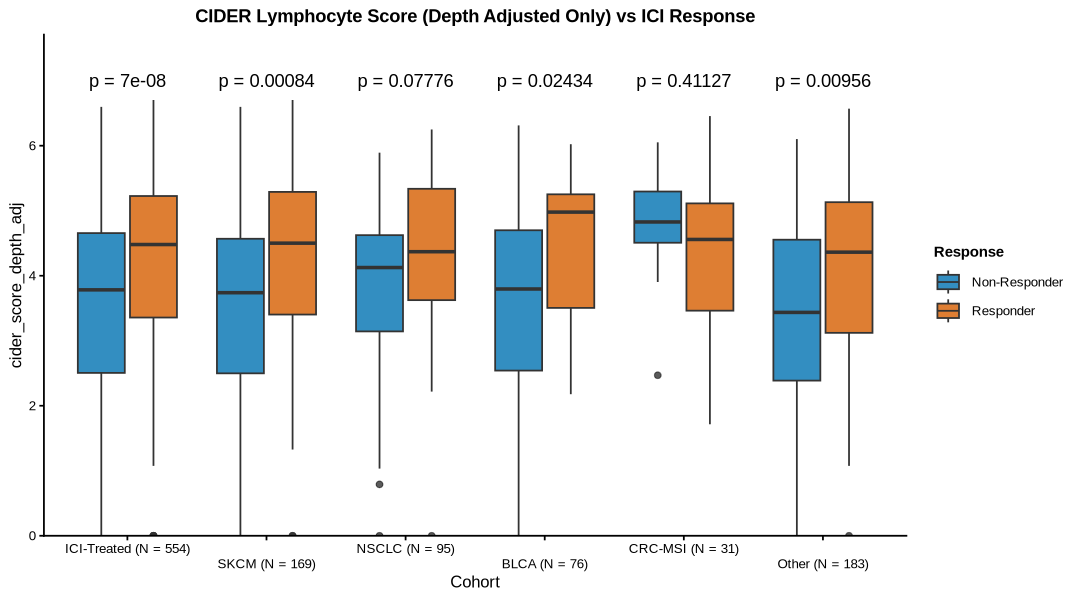

In [7]:
# Sensitivity analysis: purity-corrected score (mirrors Figure S6)
main_response_figure_depth <- response_plot(
  ready, "T-cell", "cohort_broad_go",
  title = "CIDER T-cell Score vs ICI Response (Purity Adjusted)",
  y_col = "cider_score_adj"
)
set_plot_dims(9, 4); main_response_figure_depth
saveRDS(main_response_figure_depth, paste0(CIDER_PROJ_DIR, "figs/main_response_figure_depth.rds"))

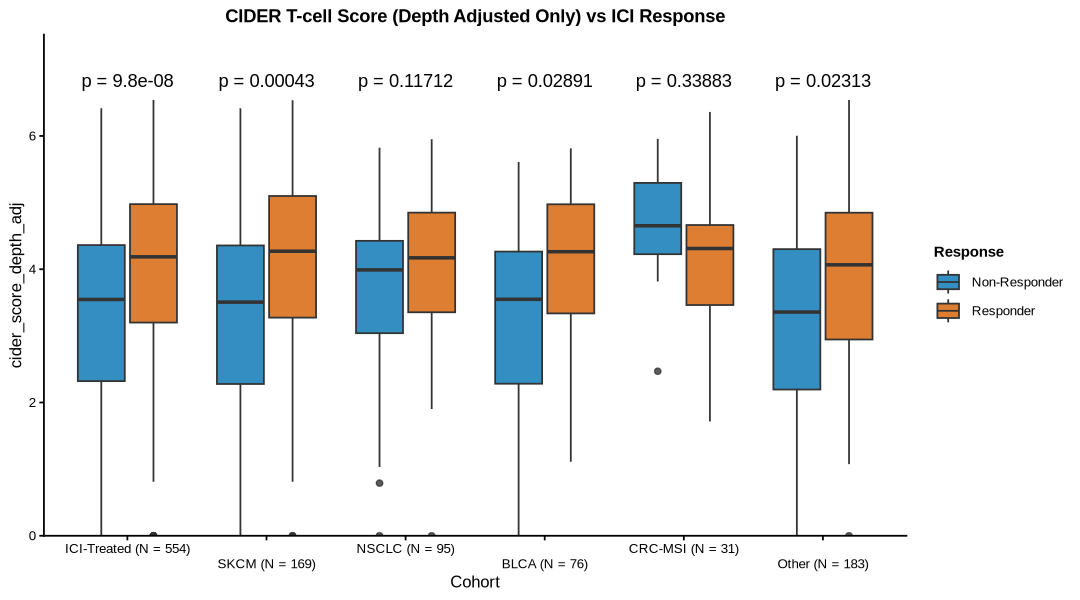

In [8]:
supporting_response_tcell_depth <- response_plot(
  ready, "T-cell", "cohort_broad_go",
  title = "CIDER T-cell Score vs ICI Response",
  y_col = "cider_score_depth_adj"
)
set_plot_dims(9, 4); supporting_response_tcell_depth

# 3 - Supporting: T-cell compartment

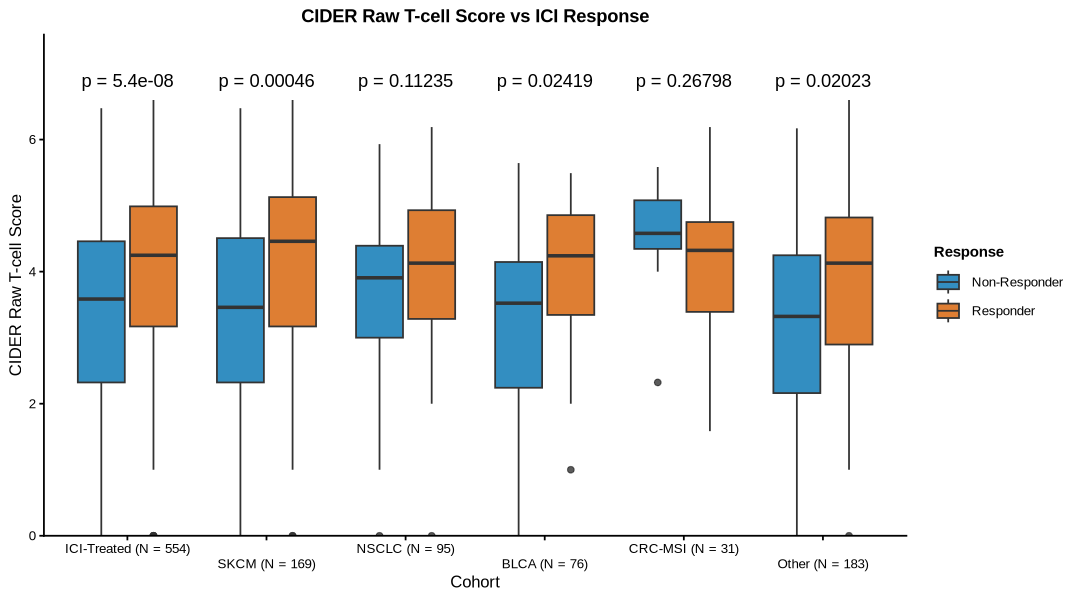

In [9]:
supporting_response_tcell <- response_plot(
  ready, "T-cell", "cohort_broad_go",
  title = "CIDER Raw T-cell Score vs ICI Response"
)
set_plot_dims(9, 4); supporting_response_tcell

- CIDER Score

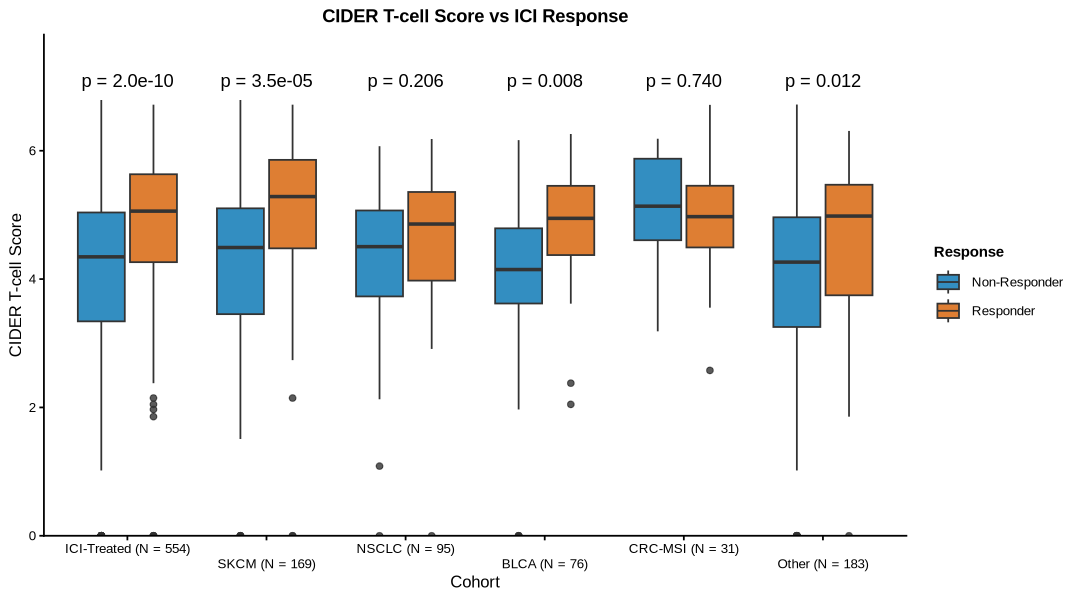

In [10]:
supporting_response_tcell_adj <- response_plot(
  ready, "T-cell", "cohort_broad_go",
  title = "CIDER T-cell Score vs ICI Response",
  y_col = "cider_score_adj"
)
set_plot_dims(9, 4); supporting_response_tcell_adj

# 5 - Supplementary: Low purity status vs ICI response

Tests whether PURPLE `WARN_LOW_PURITY` samples are enriched or depleted
among responders — a key quality check to ensure the CIDER purity correction
is not confounded by samples where purity is unreliable.

Two panels:
  A) Bar chart: proportion of responders vs non-responders with low-purity flag
  B) Boxplot: purity distribution by response, faceted by cohort

In [ ]:
# Derive low_purity flag from PURPLE QCStatus
purity_check <- ready |>
  filter(gp == "T-cell") |>
  mutate(low_purity = ifelse(QCStatus == "WARN_LOW_PURITY", "Low Purity", "Normal Purity"))

# ── Panel A: proportion of low-purity samples by response ────────────────────
prop_df <- purity_check |>
  drop_na(responder, low_purity) |>
  group_by(responder, low_purity) |>
  summarise(n = n(), .groups = "drop") |>
  group_by(responder) |>
  mutate(prop = n / sum(n) * 100) |>
  ungroup()

# Fisher's exact test on 2×2 contingency table (responder × low_purity flag)
contingency <- purity_check |>
  drop_na(responder, low_purity) |>
  with(table(responder, low_purity))
fisher_p  <- fisher.test(contingency)$p.value
fisher_lbl <- fmt_pval(fisher_p)

p_purity_prop <- prop_df |>
  ggplot(aes(x = responder, y = prop, fill = low_purity)) +
  geom_col(width = 0.6) +
  geom_text(aes(label = paste0(round(prop, 1), "%")),
            position = position_stack(vjust = 0.5),
            size = 3, colour = COL_INK, fontface = "bold") +
  annotate("text", x = 1.5, y = 103,
           label = fisher_lbl,
           size = 3.2, hjust = 0.5) +
  annotate("segment", x = 1, xend = 2, y = 101, yend = 101,
           linewidth = 0.4, colour = COL_INK) +
  # "Low Purity" is the notable QC-flag state here (not a Responder-style
  # positive), so it takes the general accent colour; "Normal Purity" is the
  # baseline and takes the negative/reference colour (rule 3/6).
  scale_fill_manual(
    values = c("Low Purity" = COL_ACCENT, "Normal Purity" = COL_NEGATIVE),
    name   = "Purity Status"
  ) +
  scale_y_continuous(labels = function(x) paste0(x, "%"),
                     expand = expansion(mult = c(0, 0.12))) +
  go_theme +
  labs(
    title = "Low Purity Flag Proportion by Response",
    x     = "Response",
    y     = "% of Patients"
  )

# ── Panel B: purity distribution by response, per cohort ─────────────────────
med_labels_purity <- purity_check |>
  drop_na(responder, purity) |>
  dplyr::group_by(cohort_broad_go, responder) |>
  dplyr::summarise(med = median(purity, na.rm = TRUE), .groups = "drop") |>
  dplyr::mutate(med_label = sprintf("%.0f%%", med * 100))

jitter_purity <- purity_check |>
  drop_na(responder, purity) |>
  dplyr::group_by(cohort_broad_go, responder) |>
  dplyr::slice_sample(n = 150) |>
  dplyr::ungroup()

p_purity_dist <- purity_check |>
  drop_na(responder, purity) |>
  ggplot(aes(x = cohort_broad_go, y = purity, fill = responder)) +
  geom_jitter(
    data     = jitter_purity,
    aes(colour = responder),
    position = position_jitterdodge(jitter.width = 0.15, dodge.width = 0.75),
    alpha = 0.2, size = 0.5, show.legend = FALSE
  ) +
  scale_colour_manual(values = responder_colors, guide = "none") +
  geom_boxplot(alpha = 0.7, outlier.shape = NA) +
  geom_text(
    data        = med_labels_purity,
    aes(x = cohort_broad_go, y = med, label = med_label, group = responder),
    inherit.aes = FALSE,
    position    = position_dodge(width = 0.75),
    vjust = -0.4, size = 2.2, fontface = "bold", colour = COL_INK
  ) +
  go_theme +
  theme(plot.title = element_text(size = 11, face = "bold", hjust = 0.5)) +
  scale_fill_manual(values = responder_colors, name = "Response") +
  stat_compare_means(
    aes(group = responder), method = "wilcox.test",
    label = "p.format", digits = 2, vjust = -0.3, size = 3.1
  ) +
  scale_y_continuous(
    limits = c(0, 1),
    breaks = c(0.2, 0.5, 1.0),
    labels = scales::percent_format(accuracy = 1),
    expand = expansion(mult = c(0, 0.05))
  ) +
  coord_cartesian(clip = "off") +
  labs(
    title = "Tumour Purity by ICI Response",
    x     = "Cohort",
    y     = "Tumour Purity"
  )

# ── Combine ───────────────────────────────────────────────────────────────────
p_purity_supp <- (p_purity_prop | p_purity_dist) +
  plot_layout(widths = c(1, 2.5)) +
  figure_annotation("Purity QC: Low-Purity Status and Tumour Purity vs ICI Response")

set_plot_dims(12, 4.5); p_purity_supp
saveRDS(p_purity_dist, paste0(CIDER_PROJ_DIR, "figs/purity_dist.rds"))